# IA 2 — TP2
## Les joueurs du jeu en ligne

**Nom :** Laura Sorro

### Répartition du travail 
Travail individuel

| Section | Responsable |
|---|---|
| 1. Découvrir les données | Seule |
| 2. Le supervisé | Seule |
| 3. Le non supervisé | Seule |
| 4. Le semi-supervisé | Seule |
| 5. Conclusion | Seule |

### Comment travailler dans ce carnet

- Exécutez les cellules **dans l'ordre**, de haut en bas.
- Chaque question vous dit **le but**, **ce que fait la cellule** et **ce que vous devez faire**.
- Dans le code, il n'y a qu'**un seul endroit à compléter** par cellule (parfois aucun) : il est marqué `...` et commenté `# ← à compléter`.
- Sous chaque question, une cellule **Observation** pose quelques petites questions. Répondez à chacune en une ou deux phrases, avec les nombres que vous avez obtenus.
- Si une cellule plante, relisez le message d'erreur, puis vérifiez que les cellules précédentes ont bien été exécutées.

## La situation

Un studio de jeu vidéo veut mieux connaître les joueurs de son jeu en ligne, pour adapter ses événements et ses récompenses. Il dispose de sept mesures sur **700 joueurs**. Pour ces 700 joueurs, une gestionnaire de communauté a examiné l'historique de chaque compte et noté son style de jeu : **occasionnel**, **compétitif** ou **explorateur**.

Le jeu compte des centaines de milliers de joueurs. Le studio veut savoir si l'IA peut retrouver les styles de jeu toute seule, et combien de comptes la gestionnaire doit vraiment examiner.

| Colonne | Signification |
|---|---|
| `heures_semaine` | temps de jeu par semaine, en heures |
| `xp_semaine` | points d'expérience gagnés par semaine |
| `parties_classees_%` | part des parties jouées en mode classé, en % |
| `zones_explorees` | nombre de zones différentes de la carte visitées dans le mois |
| `achats_mois_$` | achats dans le jeu par mois, en $ |
| `amis_en_ligne` | nombre d'amis avec qui le joueur a joué dans le mois |
| `heure_connexion` | heure habituelle de connexion (0 à 23) |

La gestionnaire met environ **20 minutes** par compte pour poser son étiquette.

*Les données sont simulées, mais construites pour ressembler à une situation réelle.*

In [1]:
# Cellule de départ — exécutez-la sans la modifier.
import warnings
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.semi_supervised import LabelSpreading
warnings.filterwarnings("ignore")

In [2]:
# Les données — exécutez cette cellule sans la modifier.
# Le fichier joueurs.csv doit être dans le même dossier que ce carnet.
import csv
with open("joueurs.csv", encoding="utf-8") as fichier:
    lignes = list(csv.reader(fichier))

colonnes = lignes[0][:-1]                                   # les 7 mesures (la dernière colonne est le style)
classes = ["occasionnel", "competitif", "explorateur"]
X = np.array([[float(v) for v in ligne[:-1]] for ligne in lignes[1:]])    # X : les mesures
y = np.array([classes.index(ligne[-1]) for ligne in lignes[1:]])          # y : le style, en numéro (0, 1 ou 2)
print("Données chargées.")

Données chargées.


---
# 1. Découvrir les données
*En équipe de 2 : ensemble, avant de vous répartir les sections 2, 3 et 4.*

### Question 1.1 — Les classes et les mesures

**Le but :** savoir combien de joueurs on a, de quels styles, et à quelle échelle sont les mesures.

**Ce que fait la cellule :** elle affiche la taille de `X`, le nombre de joueurs de chaque style, puis le minimum et le maximum de chaque colonne.

**À faire :**

1. Remplacez le `...` pour compter les joueurs de la classe `i` : c'est le nombre de fois où `y` vaut `i`.
2. Exécutez la cellule et lisez les trois blocs de résultats.

In [3]:
print("forme de X :", X.shape)        # (nombre de joueurs, nombre de mesures)
print()
for i, nom in enumerate(classes):
    nombre = np.sum(y == i)                      # ← à compléter
    print(f"{nom:15s} : {nombre} joueurs")
print()
for j, nom in enumerate(colonnes):
    colonne = X[:, j]
    print(f"{nom:20s} min = {colonne.min():>9.1f}   max = {colonne.max():>9.1f}")

forme de X : (700, 7)

occasionnel     : 300 joueurs
competitif      : 250 joueurs
explorateur     : 150 joueurs

heures_semaine       min =       0.0   max =      92.6
xp_semaine           min =       0.0   max =   80000.0
parties_classees_%   min =       0.0   max =     100.0
zones_explorees      min =       0.0   max =      80.0
achats_mois_$        min =       0.0   max =      64.0
amis_en_ligne        min =       0.0   max =      31.0
heure_connexion      min =       0.0   max =      23.0


**Observation 1.1**

1. *Combien de joueurs et combien de mesures avez-vous ?*

   Votre réponse : J'ai 700 joueurs et 7 mesures.

2. *Les trois styles ont-ils la même taille ? Lequel est le plus petit ?*

   Votre réponse : Les trois styles ont des tailles différentes : la plus grande, le style occasionnel, comprend 300 joueurs, ce qui vaut 42,9 % des 700 joueurs. Ensuite la moyenne, le style compétitif, comprend 250 joueurs, ce qui vaut 35,7 %. Enfin le plus petit style, explorateur, comprend 150 joueurs, ce qui vaut 21,4 % des 700 joueurs.

3. *Quelle colonne a les plus grands nombres ? Pourquoi est-ce un problème pour un calcul de distance ?*

   Votre réponse : La colonne 'xp_semaine' a les plus grands nombres : elle va jusqu’à 80 000 XP, alors que les autres ne dépassent pas 100. Son maximum est 800 fois plus grand que celui de 'parties_classees_%'. Dans un calcul de distance, la colonne 'xp_semaine' décide presque seule, et les autres colonnes sont écrasées. Il faut donc mettre à l'échelle avant K-Means.


### Question 1.2 — Un premier dessin

**Le but :** voir si les styles de jeu forment des paquets séparés.

**Ce que fait la cellule :** elle dessine chaque joueur selon deux colonnes, avec une couleur par style.

**À faire :**

1. Mettez `"parties_classees_%"` dans `COL_X`, puis exécutez. La colonne `COL_Y` est déjà choisie.
2. Changez ensuite `COL_X` pour `"heures_semaine"`, exécutez à nouveau et comparez.
3. Remettez la première colonne avant de passer à la suite.

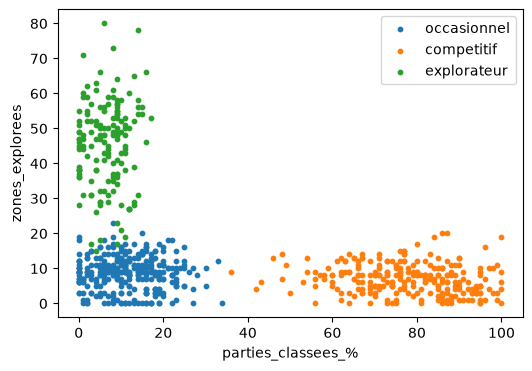

In [4]:
COL_X = "parties_classees_%"                          # ← à compléter : un nom de colonne, entre guillemets
COL_Y = "zones_explorees"

jx, jy = colonnes.index(COL_X), colonnes.index(COL_Y)
plt.figure(figsize=(6, 4))
for i, nom in enumerate(classes):
    plt.scatter(X[y == i, jx], X[y == i, jy], s=10, label=nom)
plt.xlabel(COL_X)
plt.ylabel(COL_Y)
plt.legend()
plt.show()

**Observation 1.2**

1. *Avec la première paire, les trois styles forment-ils des paquets séparés ?*

   Votre réponse : Oui les trois styles forment des paquets bien séparés quand nous comparons les "parties_classees_%" avec les "zones_explorees". Les joueurs compétitifs ont 40 à 100% de parties classées et explorent de 0 à 20 zones par mois. Les joueurs explorateurs sont bien distingués des joueurs occasionnels sur l’axe vertical, à partir de 20 zones. Entre 15 et 20 zones quelques joueurs explorateurs se mélangent avec les joueurs occasionnels. 

2. *Avec `heures_semaine`, que remarquez-vous chez les joueurs compétitifs ? Forment-ils un seul paquet ?*

   Votre réponse : Les joueurs compétitifs ne forment pas un seul paquet, nous pouvons voir clairement 2 paquets. Le paquet principal commence vers 10 heures jusqu’à 40 heures par semaine de jeux. Ensuite le 2e paquet compte près de 40 joueurs ayant entre 53 et 93 heures de jeux environ. Il y a un point orange isolé entre les deux (à environ 45 heures). Ils explorent entre 0 et 20 zones dans les 40 heures, ensuite moins de 8 zones au-delà de ces heures. La plus forte concentration du paquet principal se situe entre 20 et 30 heures, puis entre 0 et 10 zones explorées.

3. *Quels styles se mélangent le plus ?*

   Votre réponse : Les styles qui se mélangent le plus sont les joueurs occasionnels (en bleu), avec les joueurs compétitifs. Je l’observe sur le graphique « heures_semaine » versus « zones_explorees ». Le mélange se fait entre 5 et 15 heures environ par semaine, sur 5 à 12 zones explorées par mois. Sur le 1er graphique, ces 2 styles ne se mélangent pas du tout, ce sont plutôt les styles occasionnels et explorateurs. Cela montre que le choix des colonnes est important, une seule paire de colonnes ne suffit pas à séparer les trois styles.


---
# 2. Le supervisé : la référence
On commence par le cas confortable : **toutes** les étiquettes sont connues. Ce résultat servira de point de comparaison.

### Question 2.1 — Entraîner une forêt

**Le but :** mesurer ce qu'on obtient quand on connaît toutes les réponses.

**Ce que fait la cellule :** elle sépare les données (70 % pour entraîner, 30 % pour tester), entraîne une forêt aléatoire, puis calcule sa note sur le test.

**À faire :**

1. Remplacez le `...` : la forêt doit apprendre avec les mesures **et** les étiquettes d'entraînement.
2. Exécutez la cellule.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

foret = RandomForestClassifier(random_state=0)
foret.fit(X_train, y_train)                                # ← à compléter
note_foret = round(100 * foret.score(X_test, y_test), 1)

print(len(X_train), "joueurs pour entraîner,", len(X_test), "pour tester")
print("note de la forêt :", note_foret, "%")

490 joueurs pour entraîner, 210 pour tester
note de la forêt : 99.0 %


**Observation 2.1**

1. *Quelle note obtient la forêt ?*

   Votre réponse : La note qu’obtient la forêt est de 99.0 % sur 210 joueurs testés (208 joueurs bien classés et 2 erreurs).

2. *Pourquoi teste-t-on sur des joueurs que la forêt n'a jamais vus ?*

   Votre réponse : Nous testons sur des joueurs que la forêt n’a jamais vus, car nous voulons nous assurer que la forêt a vraiment appris à reconnaître les styles. Si nous testons sur des joueurs qui ont déjà été vus pendant l’entraînement, nous ne saurons pas si la forêt a appris par cœur. Si nous testons la forêt sur ses propres exemples, la note de la forêt ne vaudrait pas grand-chose : nous voulons nous assurer que les nouveaux joueurs sont bien classés. Le test sur des joueurs jamais vus permet de repérer le surapprentissage.


### Question 2.2 — Style par style, et le prix des étiquettes

**Le but :** voir si tous les styles sont aussi bien reconnus, et combien ont coûté les étiquettes.

**Ce que fait la cellule :** elle affiche, pour chaque style, la part des joueurs du test bien reconnus. Elle calcule ensuite le temps qu'il a fallu à la gestionnaire pour étiqueter l'ensemble d'entraînement.

**À faire :**

1. Remplacez le `...` par le nombre de minutes par compte (voir *La situation*).
2. Exécutez la cellule.

In [6]:
def par_classe(modele, X_t, y_t):
    pred = modele.predict(X_t)
    for i, nom in enumerate(classes):
        bons = (pred[y_t == i] == i).mean()
        print(f"{nom:15s} : {round(100 * bons, 1)} % bien reconnus")

par_classe(foret, X_test, y_test)

MINUTES_PAR_COMPTE = 20                         # ← à compléter
heures = len(y_train) * MINUTES_PAR_COMPTE / 60
print()
print("coût des étiquettes d'entraînement :", round(heures, 1), "heures")

occasionnel     : 98.8 % bien reconnus
competitif      : 100.0 % bien reconnus
explorateur     : 97.9 % bien reconnus

coût des étiquettes d'entraînement : 163.3 heures


**Observation 2.2**

1. *Quel style est le moins bien reconnu ?*

   Votre réponse : Le style le moins bien reconnu est celui des joueurs explorateurs, avec 97,9 %. Les occasionnels sont reconnus à 98,8 %, et enfin les mieux reconnus sont les compétitifs à 100,0 %. Les écarts ne sont pas significatifs entre les styles. Il y a 48 explorateurs dans le test (le test contient 30 % des 700 joueurs, tirés au hasard). Sur ces 48 explorateurs, une erreur d’un joueur fait perdre environ 2 points de pourcentage. L’écart entre 97,9 % et 98,8 % ne veut presque rien dire. Il y a une erreur chez les occasionnels aussi (98,8% de 81 joueurs testés). 1 erreur chez les explorateurs + 1 erreur chez les occasionnels, cela équivaut aux 2 erreurs que nous avons trouvées dans la question 2.1.

2. *Combien d'heures ont coûté les étiquettes ? Est-ce réaliste pour des centaines de milliers de joueurs ?*

   Votre réponse : Les étiquettes ont coûté 163,3 heures de travail de la gestionnaire. C’est beaucoup! Sur 40h par semaine, cela équivaut à 4 semaines de travail à temps plein, pour seulement étiqueter 490 comptes. Si nous poussons ce calcul pour 100 000 joueurs, le résultat serait de : 33 333 heures (100 000 × 20 ÷ 60), soit environ 18 ans de travail à temps plein ! C’est un grand coût pour le studio, trop grand. 

3. *La forêt ne peut répondre que par les trois styles que la gestionnaire a utilisés. S'il existait un quatrième type de joueur que personne n'a jamais nommé, la forêt pourrait-elle le découvrir ?*

   Votre réponse : Non, elle ne peut pas découvrir ce qui ne lui a pas été donné, elle ne peut pas inventer un autre style. Elle ne signalerait pas un 4ᵉ type. 
   Avec un joueur inconnu, la forêt doit répondre par l’un des trois styles connus. Elle le classe dans celui qui lui ressemble le plus, sans nous prévenir. Si nous prenons les compétitifs qui ont 100% de réussite, rappelons-nous qu’à la question 1.2 nous avions découvert un petit paquet isolé entre 50 et 90h. Si ces joueurs étaient un 4ᵉ type, la note parfaite l’aurait caché sans le faire exprès. 
   La méthode qui pourrait découvrir ce groupe serait la méthode qui cherche des groupes sans étiquettes, c’est-à-dire le non supervisé (K-Means). 



---
# 3. Le non supervisé : chercher sans étiquettes
Dans cette section, **K-Means ne voit jamais `y`**. On ne s'en sert qu'après coup, pour vérifier ce qu'il a trouvé.

### Question 3.1 — K-Means, avant et après la mise à l'échelle

**Le but :** voir si K-Means retrouve les trois styles tout seul, et l'effet de la mise à l'échelle.

**Ce que fait la cellule :** elle lance deux fois K-Means avec 3 groupes : d'abord sur les mesures brutes, puis sur les mesures mises à l'échelle. Pour chaque groupe, elle affiche les vrais styles qu'il contient.

**À faire :**

1. Remplacez le `...` pour mettre `X` à l'échelle avec `StandardScaler`.
2. Exécutez la cellule et comparez les deux blocs de résultats.

In [ ]:
def contenu(groupes, k):
    for g in range(k):
        noms = [classes[i] for i in y[groupes == g]]          # y sert seulement à vérifier
        print(f"groupe {g} : {len(noms):4d} joueurs ->", dict(Counter(noms)))

print("--- SANS mise à l'échelle")
groupes_brut = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X)
contenu(groupes_brut, 3)

X_echelle = ...                           # ← à compléter
print()
print("--- APRÈS mise à l'échelle")
groupes = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X_echelle)
contenu(groupes, 3)

**Observation 3.1**

1. *Sans mise à l'échelle, chaque groupe correspond-il à un style, ou est-ce un mélange ? Quelle colonne a décidé des groupes ?*

   Votre réponse :

2. *Après la mise à l'échelle, quels styles sont mis ensemble dans un même groupe ?*

   Votre réponse :

3. *Un groupe ne contient que des « compétitifs », mais il est beaucoup plus petit que les autres. Combien de joueurs contient-il ? Gardez-le en tête pour la suite.*

   Votre réponse :


### Question 3.2 — Combien de groupes ? Le coude

**Le but :** choisir le nombre de groupes sans connaître les réponses.

**Ce que fait la cellule :** elle calcule l'inertie de K-Means pour k = 1 à 8 et dessine la courbe. Elle affiche ensuite le contenu des groupes avec 3 puis 4 groupes.

**À faire :**

1. Remplacez le `...` : chaque tour entraîne K-Means avec `k` groupes sur `X_echelle`.
2. Exécutez la cellule, regardez la courbe, puis comparez le contenu avec 3 et avec 4 groupes.

In [ ]:
valeurs = []
for k in range(1, 9):
    modele = ...                                       # ← à compléter
    valeurs.append(round(modele.inertia_))
print("inertie pour k = 1 à 8 :", valeurs)

plt.figure(figsize=(5, 3))
plt.plot(range(1, 9), valeurs, marker="o")
plt.xlabel("nombre de groupes k")
plt.ylabel("inertie")
plt.show()

for k in [3, 4]:
    print()
    print(f"--- avec {k} groupes")
    contenu(KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X_echelle), k)

**Observation 3.2**

1. *Où voyez-vous le coude ? Quel nombre de groupes suggère-t-il ?*

   Votre réponse :

2. *Avec 4 groupes, les trois styles de la gestionnaire sont-ils enfin séparés ?*

   Votre réponse :

3. *Combien de groupes y a-t-il au total avec k = 4, alors que la gestionnaire n'utilise que trois styles ? Qu'en concluez-vous ?*

   Votre réponse :


### Question 3.3 — Décrire et dessiner les groupes

**Le but :** donner un sens à chaque groupe trouvé, comme si vous le présentiez au studio.

**Ce que fait la cellule :** elle relance K-Means avec votre nombre de groupes, affiche la **moyenne de chaque mesure** dans chaque groupe (dans les unités d'origine), puis dessine les joueurs avec l'ACP : à gauche colorés par K-Means, à droite par les vrais styles.

**À faire :**

1. Remplacez le `...` par le nombre de groupes que vous avez choisi en 3.2.
2. Exécutez la cellule.
3. Remplissez le tableau sous la cellule : un nom et une description pour chaque groupe.

In [ ]:
K_CHOISI = ...                                       # ← à compléter
groupes_choisis = KMeans(n_clusters=K_CHOISI, n_init=10, random_state=0).fit_predict(X_echelle)
contenu(groupes_choisis, K_CHOISI)
print()
for g in range(K_CHOISI):
    moyennes = X[groupes_choisis == g].mean(axis=0)            # mesures d'origine, pas X_echelle
    print(f"groupe {g} :", {nom: round(float(v), 1) for nom, v in zip(colonnes, moyennes)})

deux = PCA(n_components=2).fit_transform(X_echelle)        # l'ACP : 7 mesures -> 2 nombres
couleurs = np.array(["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown", "tab:pink", "tab:gray"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(deux[:, 0], deux[:, 1], c=couleurs[groupes_choisis], s=10)
axes[0].set_title("Groupes de K-Means (sans étiquettes)")
axes[1].scatter(deux[:, 0], deux[:, 1], c=couleurs[y], s=10)
axes[1].set_title("Vrais styles (ajoutés après coup)")
for a in axes:
    a.set_xlabel("composante 1")
    a.set_ylabel("composante 2")
plt.show()

| Groupe | Nom que vous lui donnez | Ce qui le caractérise (avec les moyennes) |
|---|---|---|
| 0 | | |
| 1 | | |
| … | | |

**Observation 3.3**

1. *Quel nombre de groupes avez-vous choisi, et pourquoi ?*

   Votre réponse :

2. *Regardez les moyennes du petit groupe de « compétitifs ». Ces comptes vous semblent-ils joués par des humains ? Qu'est-ce que c'est, selon vous ?*

   Votre réponse :

3. *Pourquoi la gestionnaire ne les a-t-elle pas repérés, et pourquoi le studio voudrait-il les trouver ?*

   Votre réponse :


---
# 4. Le semi-supervisé : quelques étiquettes seulement
Situation réaliste : la gestionnaire n'a examiné que **quelques** comptes. On garde l'ensemble d'entraînement de la section 2, mais on cache presque toutes ses étiquettes.

### Question 4.1 — La forêt contre le semi-supervisé, avec 3 étiquettes par style

**Le but :** comparer deux façons d'apprendre avec très peu d'étiquettes.

**Ce que fait la cellule :** la fonction `garder` ne garde que `n` étiquettes par style et cache toutes les autres. La fonction `comparer` entraîne une forêt avec les seuls joueurs étiquetés, et un modèle semi-supervisé avec **tous** les joueurs (étiquetés ou non). La cellule les compare avec 3 étiquettes par style.

**À faire :**

1. Remplacez le `...` par la valeur qui veut dire « pas d'étiquette » pour scikit-learn.
2. Exécutez la cellule.

In [ ]:
Xe_train, Xe_test, y_train, y_test = train_test_split(X_echelle, y, test_size=0.3, random_state=0)

def garder(n, tirage):
    hasard = np.random.RandomState(tirage)
    gardes = np.concatenate([hasard.choice(np.where(y_train == i)[0], n, replace=False)
                             for i in range(len(classes))])
    y_partiel = np.full(len(y_train), ...)                # ← à compléter
    y_partiel[gardes] = y_train[gardes]                    # on remet seulement les étiquettes gardées
    return gardes, y_partiel

def comparer(n, tirage):
    gardes, y_partiel = garder(n, tirage)
    foret_peu = RandomForestClassifier(random_state=0).fit(Xe_train[gardes], y_train[gardes])
    semi = LabelSpreading(kernel="knn", n_neighbors=7, max_iter=1000).fit(Xe_train, y_partiel)
    return foret_peu, semi

gardes, y_partiel = garder(3, 0)
print("étiquettes gardées :", len(gardes), "sur", len(y_train))
foret_peu, semi = comparer(3, 0)
print("forêt, étiquetés seulement :", round(100 * foret_peu.score(Xe_test, y_test), 1), "%")
print("semi-supervisé             :", round(100 * semi.score(Xe_test, y_test), 1), "%")
print()
print("semi-supervisé, style par style :")
par_classe(semi, Xe_test, y_test)

**Observation 4.1**

1. *Combien d'étiquettes gardez-vous, sur combien ?*

   Votre réponse :

2. *Qui fait mieux avec ces quelques étiquettes : la forêt ou le semi-supervisé ? Comparez aussi avec la forêt de la section 2.*

   Votre réponse :

3. *Quel style le semi-supervisé reconnaît-il le moins bien ? Avez-vous une idée de qui sont les joueurs mal reconnus ?*

   Votre réponse :


### Question 4.2 — Combien d'étiquettes faut-il ?

**Le but :** trouver le nombre d'étiquettes à partir duquel on obtient de bons résultats.

**Ce que fait la cellule :** elle refait la comparaison de 4.1 avec 1, 2, 3, 5, 10 et 20 étiquettes par style. Pour chaque nombre, elle fait 5 tirages au hasard et garde la moyenne, puis elle dessine les deux courbes.

**À faire :**

1. Il n'y a rien à compléter : exécutez la cellule (elle prend quelques secondes).
2. Lisez le tableau et la courbe.

In [ ]:
liste_n = [1, 2, 3, 5, 10, 20]
moy_foret, moy_semi = [], []
for n in liste_n:
    notes_f, notes_s = [], []
    for tirage in range(5):                                  # 5 tirages différents
        f, s = comparer(n, tirage)
        notes_f.append(100 * f.score(Xe_test, y_test))
        notes_s.append(100 * s.score(Xe_test, y_test))
    moy_foret.append(round(np.mean(notes_f), 1))
    moy_semi.append(round(np.mean(notes_s), 1))
    print(f"{n:2d} étiquette(s) par style : forêt {moy_foret[-1]:5.1f} %   semi {moy_semi[-1]:5.1f} %")

plt.figure(figsize=(6, 3.5))
plt.plot(liste_n, moy_foret, marker="o", label="forêt (étiquetés seulement)")
plt.plot(liste_n, moy_semi, marker="o", label="semi-supervisé")
plt.xlabel("étiquettes par style")
plt.ylabel("note sur le test (%)")
plt.legend()
plt.show()

**Observation 4.2**

1. *Avec 1 seule étiquette par style, quel modèle fait le mieux ? De combien ?*

   Votre réponse :

2. *À partir de combien d'étiquettes par style chacun des deux modèles atteint-il 95 % ?*

   Votre réponse :

3. *Le semi-supervisé semble plafonner un peu sous la forêt. Proposez une explication, en pensant au petit groupe trouvé en section 3.*

   Votre réponse :


### Question 4.3 — Une étiquette dans le petit groupe

**Le but :** vérifier si les erreurs du semi-supervisé viennent du petit groupe trouvé en section 3, et comment les corriger.

**Ce que fait la cellule :** elle repère les joueurs de ce petit groupe grâce à K-Means, puis mesure combien d'entre eux sont bien reconnus par le semi-supervisé de la question 4.1. Elle ajoute ensuite **une seule** étiquette : un joueur de ce petit groupe, étiqueté « compétitif » comme l'a fait la gestionnaire, et refait le semi-supervisé.

**À faire :**

1. Remplacez le `...` par le numéro du petit groupe de « compétitifs » trouvé à la question 3.3 (lisez le contenu des groupes).
2. Exécutez la cellule et comparez les deux résultats.

In [ ]:
GROUPE_PETIT = ...                                   # ← à compléter : le numéro du groupe, à la question 3.3
dans_petit = (groupes_choisis == GROUPE_PETIT)
_, _, petit_train, petit_test = train_test_split(X_echelle, dans_petit, test_size=0.3, random_state=0)   # même découpage qu'en 4.1

def bilan(modele):
    pred = modele.predict(Xe_test)
    comp = (y_test == 1)
    print(f"  joueurs du petit groupe   : {round(100 * (pred[petit_test] == 1).mean(), 1)} % reconnus « compétitif »")
    print(f"  autres joueurs compétitifs : {round(100 * (pred[comp & ~petit_test] == 1).mean(), 1)} % reconnus « compétitif »")
    print(f"  note globale               : {round(100 * modele.score(Xe_test, y_test), 1)} %")

gardes, y_partiel = garder(3, 0)
print("étiquettes gardées dans le petit groupe :", petit_train[gardes].sum())
print("semi-supervisé de la question 4.1 :")
bilan(LabelSpreading(kernel="knn", n_neighbors=7, max_iter=1000).fit(Xe_train, y_partiel))

y_plus = y_partiel.copy()
un_joueur = np.where(petit_train)[0][0]                    # un joueur du petit groupe
y_plus[un_joueur] = 1                                      # étiqueté « compétitif », comme l'a fait la gestionnaire
print()
print("avec UNE étiquette de plus, dans le petit groupe :")
bilan(LabelSpreading(kernel="knn", n_neighbors=7, max_iter=1000).fit(Xe_train, y_plus))

**Observation 4.3**

1. *Combien des étiquettes gardées en 4.1 venaient du petit groupe ? Quelle part de ses joueurs était bien reconnue ?*

   Votre réponse :

2. *Avec une seule étiquette de plus, qu'est-ce qui change ?*

   Votre réponse :

3. *Quelle règle en tirez-vous pour choisir les quelques comptes que la gestionnaire doit examiner ?*

   Votre réponse :


---
# 5. Conclusion
*En équipe de 2 : ensemble, une fois les sections 2, 3 et 4 intégrées.*

### Question 5.1 — Le tableau des trois familles
Complétez le tableau avec **vos** résultats.

| Famille | Étiquettes utilisées | Résultat obtenu | Ce que ça nous a appris |
|---|---|---|---|
| Supervisé (forêt) | | | |
| Non supervisé (K-Means) | | | |
| Semi-supervisé | | | |

### Question 5.2 — Votre recommandation au studio
En **8 à 12 lignes**, répondez au studio :

1. Quelle approche recommandez-vous pour connaître le style de ses joueurs, et pourquoi ?
2. Combien de comptes la gestionnaire devrait-elle examiner, et lesquels ?
3. Que devrait faire le studio au sujet du petit groupe découvert en section 3 ?

Appuyez chaque réponse sur un résultat du carnet (donnez le numéro de la question).

**Recommandation :**

*Votre texte ici.*

---
# 6. Déclaration d'utilisation de l'IA
*Obligatoire, même si vous n'avez utilisé aucun outil. Une déclaration absente ou fausse entraîne la note de 0.*

Rappel : l'IA est permise pour **apprendre** (faire expliquer une notion, un message d'erreur), interdite pour **produire** le travail. Il est interdit de coller l'énoncé, le carnet ou les données dans une conversation.

| Membre | Outil utilisé | Question visée | Ce qui a été demandé | Lien de partage de la conversation |
|---|---|---|---|---|
|Laura S. | Claude | 1.1 | Comprendre ce que renvoie y == i sur un tableau NumPy et comment compter les True | https://claude.ai/share/bf0d0e26-4f19-4267-9819-8e83970f0a67 |
|Laura S. | Claude | 1.2 | Comprendre ce que fait X[y == i, jx] et comment lire un nuage de points pour repérer des paquets séparés ou mélangés | https://claude.ai/share/20188a0b-ae10-419e-b944-91843ea0b0b9 |
| Laura S. | Claude | 2.1 | Comprendre ce que fait la méthode `.fit()` d'un classifieur, ses arguments en supervisé, et pourquoi on ne lui donne pas `X_test` | https://claude.ai/share/5c162a06-6428-45df-8457-8f2e3bc2303a |
| Laura S. | Claude | 2.2 | Comprendre le calcul `(pred[y_t == i] == i).mean()` et pourquoi on mesure la réussite classe par classe | https://claude.ai/share/a8cf6b6b-ce77-4fab-8064-15e457b3449f |
| | | | | |
| | | | | |

*Si aucun outil n'a été utilisé, écrivez-le ici pour chaque membre : « Aucun outil d'IA utilisé. »*